# Bước B0 - LSTM nền của bước B: Sequential Forecast LSTM có Q của BiasCast (cấu hình tác giả, qmean m³/s) chạy đủ 30 epoch, hạt giống 111 / 222 / 333, trên Kaggle T4
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0), config tác giả Zenodo 17292895
      - đã lưu thành Kaggle Dataset "lamah-ce-ext" (Workspace/01_Download/01_LamaHCEExt_Download/01_LamaHCEExt_Download.py).
# Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 5.1 (giao thức 30 epoch), 7 (dòng B0), 8.1 (thời gian), 9.5 (dự báo xuất ra).
 Khác A4 (Workspace/03_Baseline/03_A4_LamaHCEExt_Retrain/): chạy đủ 30 epoch (early_stopping_patience 30, vẫn lưu
 best_model.pt theo NSE trung vị validation), fork f229e02 (sửa lưu best_model.pt + data_on_gpu: dữ liệu để sẵn trên GPU,
 kết quả trùng từng bit bộ nạp cũ - Workspace/04_Setup/03_0_GPUData_Check/), chấm test cả 30 epoch để theo dõi.
 Mô hình, dữ liệu, siêu tham số, hạt giống giữ như A4; không bật chế độ tất định (như A4).
 Mỗi hạt giống một tệp và một notebook Kaggle cùng tên: "01_B0_LamaHCEExt_Train_Seed111", "..._Seed222", "..._Seed333"
 - ba tệp giống hệt nhau, chỉ khác dòng RUN_SEED ở Phần 1. So sánh 3 hạt giống, xuất NPZ cho bộ đánh giá ở notebook CPU
 "02_B0_LamaHCEExt_Compare".
# Cài đặt mỗi notebook: Accelerator = GPU T4 x2 (dùng GPU 0), Internet = On, Persistence = Files only,
 Environment = Pin to original environment, Add Input => lamah-ce-ext. Mỗi Phần dán vào 1 cell, chạy lần lượt.
 Dán nguyên tệp vào notebook rồi Save & Run All, không sửa dòng nào; Output chính thức (b0_runs/, b0_output/) lấy
 từ bản lưu đó.

# MỤC LỤC
   Phần 1 - Cài thư viện NeuralHydrology từ fork của nhóm, kiểm môi trường
   Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
   Phần 3 - Dựng thư mục dữ liệu có cột qmean
   Phần 4 - Tạo config cho hạt giống RUN_SEED
   Phần 5 - Huấn luyện hạt giống RUN_SEED (30 epoch, validation mỗi epoch)
   Phần 6 - Chấm test mọi epoch và best_model.pt, kiểm best_model.pt
   Phần 7 - Hình đường học theo epoch và loss theo bước
   Phần 8 - Ghi môi trường, danh mục tệp, dọn thư mục dữ liệu tạm

Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit f229e02),
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,
matplotlib,3.10.0,
tensorboard,2.20.0,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 29.7
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805


Điều kiện,Đạt
Cài đúng commit f229e02,ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có GPU T4 (dùng GPU 0),ĐẠT
Có tensorboard,ĐẠT
Nạp nh_run,ĐẠT
Nạp logger,ĐẠT
Nạp gpu_loader,ĐẠT
Nạp tester,ĐẠT
Nạp sequential_forecast_lstm,ĐẠT
Config có khóa data_on_gpu,ĐẠT


=> Đạt. Hạt giống 222. Chạy Phần 2.


mục,đường dẫn,ghi chú
Dữ liệu,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/lamah_ce_ext/LamaH_extended,
Kết quả tác giả,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments,
Danh sách lưu vực,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments/basins_filtered.txt,"451 lưu vực, 451 mã khác nhau"
Run tác giả: config,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/config.yml,có
Run tác giả: best_model.pt,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/best_model.pt,có
Run tác giả: scaler,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/train_data/train_data_scaler.yml,có
Run tác giả: test_metrics,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv,có


...

Chấm test: trung vị 0.85 phút/epoch, tổng 27.9 phút kể cả dựng dataset


Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


mô hình,NSE trung vị test,KGE trung vị test,lưu vực có NSE test
best_model.pt (epoch 15),0.703780,0.790980,450
"tác giả (best_model.pt, Zenodo)",0.705280,0.767070,450


mục,giá trị,cần,đạt
best_model.pt trùng tensor với đúng 1 epoch,[15],1 epoch,ĐẠT
Epoch best_model.pt = epoch Phần 5 ghi sau cùng = epoch NSE validation cao nhất (tệp),15 / 15 / 15,bằng nhau,ĐẠT
"NSE, KGE validation tệp khớp log (từng epoch)",30 / 30,sai lệch <= 0.0001,ĐẠT
Validation đủ 451 lưu vực mỗi epoch,[451],[451],ĐẠT
Có test_metrics.csv cho mọi epoch + best,30 + 1,30 + 1,ĐẠT
NSE trung vị test: kết quả trả về khớp tệp ghi,0.0e+00,<= 1e-06,ĐẠT
Test best_model.pt = test epoch cùng trọng số (NSE trung vị),0.0e+00,<= 1e-06,ĐẠT
Có cache / không cache: lệch NSE lớn nhất từng lưu vực (best_model.pt),"0.0e+00, NaN trùng: True","<= 1e-06, NaN trùng",ĐẠT
Lưu vực có NSE test (best_model.pt),450,450 (lưu vực 55 không có qmean),ĐẠT
Chỉ còn test_results.p của best_model.pt,1,1,ĐẠT


Tester không cache chấm best_model.pt: 2.4 phút
=> Đạt. Chạy Phần 7.


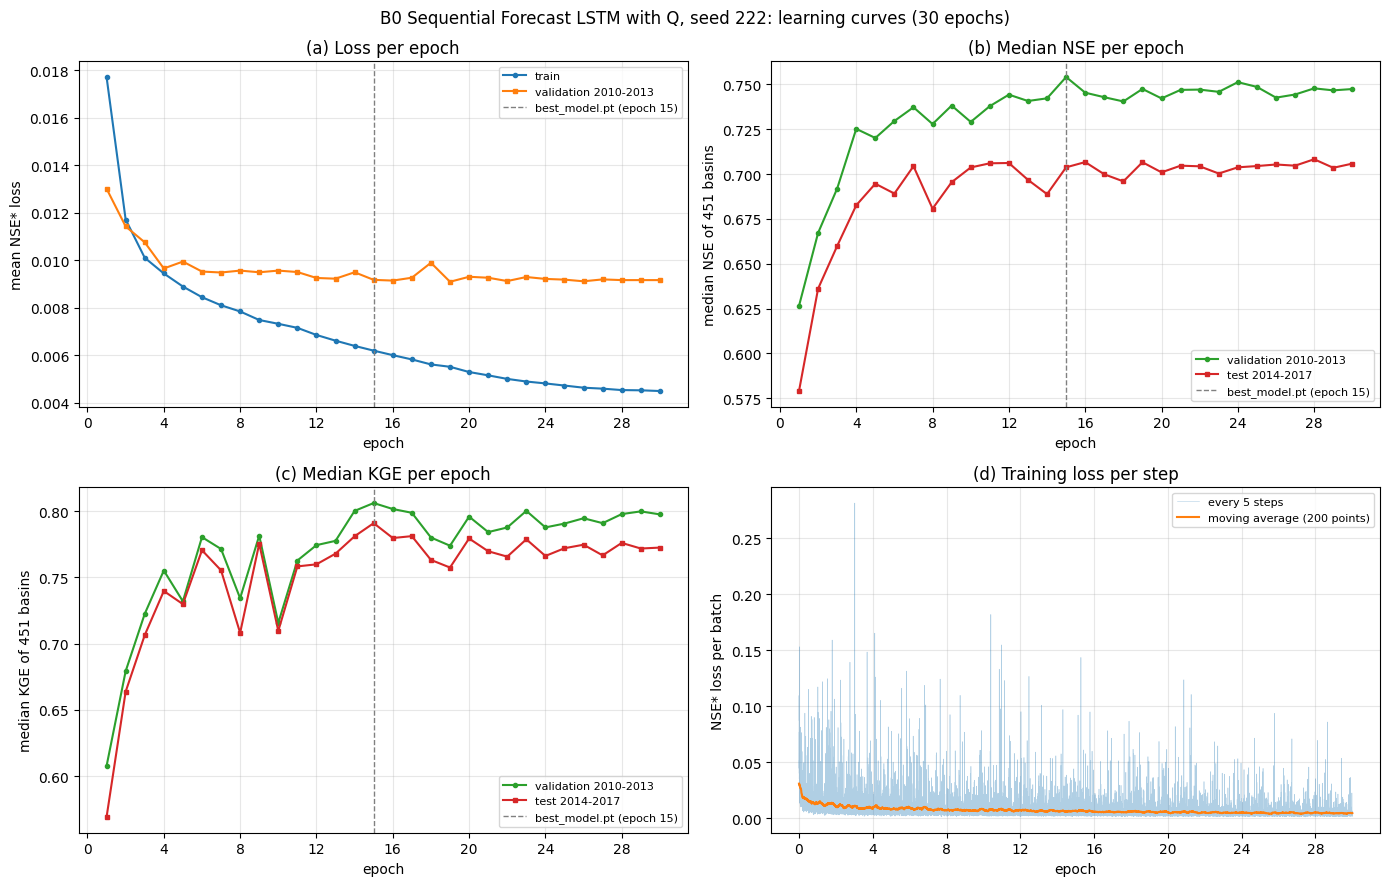

Hình: đường học của hạt giống 222 qua 30 epoch. (a) loss NSE* trung bình mỗi epoch của kỳ huấn luyện và kỳ validation; loss huấn luyện giảm trong khi loss validation tăng là dấu hiệu quá khớp. (b), (c) NSE và KGE trung vị 451 lưu vực của kỳ validation (dùng để chọn mô hình) và kỳ test (chỉ để theo dõi); vạch xám là epoch lưu thành best_model.pt (epoch 15: NSE validation 0,754, NSE test 0,704). (d) loss của từng lô 256 mẫu, ghi mỗi 5 bước (25650 điểm), đường cam là trung bình trượt 200 điểm; trục ngang đổi ra epoch (4275 bước/epoch).
Đã lưu /kaggle/working/b0_output/Figures/B0_Curve_B0_SeqLSTM_Q_seed222.png
=> Đạt. Chạy Phần 8.


tệp,KB,sha256
b0_runs/B0_SeqLSTM_Q_seed222_2510_175613/config.yml,3.800000,f8e0cf9cd8f0...
b0_runs/B0_SeqLSTM_Q_seed222_2510_175613/train_data/train_data_scaler.yml,8.400000,cf187f01309a...
b0_runs/B0_SeqLSTM_Q_seed222_2510_175613/best_model.pt,345.200000,3f2216a99ed7...
b0_runs/B0_SeqLSTM_Q_seed222_2510_175613/test/best_model/test_metrics.csv,18.800000,1ac34df22925...
b0_runs/B0_SeqLSTM_Q_seed222_2510_175613/test/best_model/test_results.p,16177.800000,558488ce9428...
b0_runs/B0_SeqLSTM_Q_seed222_2510_175613/output.log,26.100000,1b9a753cbbfb...
b0_runs/B0_SeqLSTM_Q_seed222_2510_175613/events.out.tfevents.1792951087.4561ee408a86.128.0,2735.300000,276582e9700b...


thư mục,GB
b0_configs,0.000000
b0_output,0.002000
b0_runs,0.537000


mục,giá trị,cần,đạt
Đủ tệp chính trong thư mục run,7 / 7,đủ,ĐẠT
Có tệp sự kiện tensorboard,1,>= 1,ĐẠT
test_metrics.csv theo epoch,30,30,ĐẠT
Commit thư viện đúng f229e02,f229e02,f229e02,ĐẠT
Đã xóa thư mục dữ liệu tạm,True,True,ĐẠT
Tổng Output,0.54 GB,<= 20 GB,ĐẠT


=> Đạt. Xong notebook.


In [1]:
# %% Phần 1 - Cài thư viện NeuralHydrology từ fork của nhóm, kiểm môi trường
# Cài đúng commit f229e02 của nhánh research (dda45fc + sửa lưu best_model.pt e794d7c + khóa data_on_gpu;
# 02_Pipeline.md Mục 9.1). In 3 bảng (thư viện, môi trường, điều kiện). tensorboard bắt buộc vì training/logger.py dòng 8
# nạp SummaryWriter khi import. Phần 1-5 raise khi chưa đạt để Save & Run All dừng ngay, không tốn giờ GPU cho các Phần sau.
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "f229e02bf98cbd979835a4b6cd503d0e3adb8bc3"   # nhánh research từ B0
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.nh_run", "neuralhydrology.training.logger", "neuralhydrology.datautils.gpu_loader",
              "neuralhydrology.evaluation.tester", "neuralhydrology.modelzoo.sequential_forecast_lstm"]
TORCH_A4 = "2.11.0+cu128"                # torch của A4 và notebook kiểm GPU (ảnh Kaggle 10/2026); khác thì chỉ cảnh báo

RUN_SEED = 222                           # 111 là hạt giống của tác giả (config.yml); 222, 333 như A4
assert RUN_SEED in (111, 222, 333), "RUN_SEED phải là 111, 222 hoặc 333"

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b0_work")
OUT_DIR = WORK_DIR / "b0_output"         # bảng, hình, tóm tắt, môi trường (Phần 5-8); thư mục run ở b0_runs/
WORK_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


before = installed_versions(CHECK_LIBS)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"], check=True)
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài

# Xác nhận pip cài đúng commit (pip ghi nguồn cài vào direct_url.json)
direct = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}")
installed_commit = direct.get("vcs_info", {}).get("commit_id")
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
show("Thư viện (sau khi cài fork)", pd.DataFrame({
    "Thư viện": ["neuralhydrology"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {installed_commit[:7] if installed_commit else '?'})"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] + [f"từ {before[k]}" if k in changed else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi cài để in đúng thiết bị

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng: nh_run (huấn luyện), logger (cần tensorboard), bộ nạp trên GPU, tester (chấm test
# 30 epoch ở Phần 6), mô hình SeqLSTM
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

from neuralhydrology.utils.config import Config

checks = {
    "Cài đúng commit f229e02": installed_commit == NH_COMMIT,
    "pip không đổi thư viện có sẵn": not changed,
    "Có GPU T4 (dùng GPU 0)": n_gpu >= 1 and "T4" in gpus[0],
    "Có tensorboard": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
    "Config có khóa data_on_gpu": isinstance(getattr(Config, "data_on_gpu", None), property),
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")

if torch.__version__ != TORCH_A4:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của A4 ({TORCH_A4}) - ảnh Kaggle đã đổi; ghi lại khi so sánh.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn - huấn luyện chạy ở tiến trình mới nên dùng bản mới; ghi lại khi so sánh.")
# Save & Run All không dừng ở dòng in => lỗi phải raise để không tốn giờ GPU cho các Phần sau
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print(f"=> Đạt. Hạt giống {RUN_SEED}. Chạy Phần 2.")


# %% Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
# Chỉ đọc. Tìm thư mục dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản
# (run tốt nhất của bài, cũng là run "SeqLSTM có Q" ở A2, A4), kiểm đúng run bằng các siêu tham số (như A4 Phần 2),
# rồi xếp mọi khóa config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ (khóa thư viện tự ghi sau khi chạy). So với A4 đổi
# thêm 2 khóa: early_stopping_patience 5 => 30 (chạy đủ 30 epoch mà vẫn lưu best_model.pt, basetrainer.py dòng 214-227,
# 343-369 ở f229e02) và data_on_gpu (mặc định False => True). NSE trung vị test của tác giả đọc từ test_metrics.csv (mốc so ở Phần 6).
# Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display
from ruamel.yaml import YAML

IS_KAGGLE = Path("/kaggle/working").exists()
SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("b0_work")
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
# Giá trị phải có trong config tác giả (như A4 Phần 2) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa sẽ đổi ở Phần 4 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, hạt giống, tên run như A4; thêm giao thức
# 30 epoch và dữ liệu sẵn trên GPU) và khóa bỏ
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file",
               "device", "num_workers", "verbose", "seed", "experiment_name", "early_stopping_patience", "data_on_gpu"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index"))


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, tệp của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_RUN = EXP_DIR / AUTHOR_RUN_REL
AUTHOR_FILES = {"config": AUTHOR_RUN / "config.yml", "best_model.pt": AUTHOR_RUN / "best_model.pt",
                "scaler": AUTHOR_RUN / "train_data" / "train_data_scaler.yml",
                "test_metrics": AUTHOR_RUN / "test" / "best_model" / "test_metrics.csv"}
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau")]
    + [(f"Run tác giả: {k}", str(p.relative_to(EXP_DIR)), "có" if p.exists() else "THIẾU") for k, p in AUTHOR_FILES.items()],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not all(p.exists() for p in AUTHOR_FILES.values()):
    raise RuntimeError("Thiếu tệp của run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": "qmean ở pha quá khứ, đúng 1 lần", "mong đợi": "1 lần",
              "trong config": f"{groups['hindcast_inputs'].count('qmean')} lần",
              "khớp": "ĐẠT" if groups["hindcast_inputs"].count("qmean") == 1 else "KHÔNG"},
             {"khóa": "qmean không ở pha ngày t", "mong đợi": "không",
              "trong config": "có" if "qmean" in groups["forecast_inputs"] else "không",
              "khớp": "ĐẠT" if "qmean" not in groups["forecast_inputs"] else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))

# (3) Mọi khóa config: giữ / đổi ở Phần 4 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 4" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 4": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 4')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

# (4) NSE test của tác giả (mốc so ở Phần 6)
author_metrics = pd.read_csv(AUTHOR_FILES["test_metrics"], dtype={"basin": str}).set_index("basin")
AUTHOR_TEST_NSE_MEDIAN = float(author_metrics["NSE"].median())  # pandas bỏ NaN khi tính trung vị
show("NSE test của tác giả (test_metrics.csv)", pd.DataFrame([{
    "số lưu vực": len(author_metrics), "có NSE": int(author_metrics["NSE"].notna().sum()),
    "NaN": ", ".join(author_metrics.index[author_metrics["NSE"].isna()]) or "-",
    "NSE trung vị": round(AUTHOR_TEST_NSE_MEDIAN, 6), "KGE trung vị": round(float(author_metrics["KGE"].median()), 6),
    "khớp danh sách lưu vực": "ĐẠT" if set(author_metrics.index) == set(basins) else "KHÔNG"}]))

ok = all(r["khớp"] == "ĐẠT" for r in exp_rows) and set(author_metrics.index) == set(basins)
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")


# %% Phần 3 - Dựng thư mục dữ liệu có cột qmean
# Chép nguyên A4 Phần 3 (đạt ở cả 3 hạt giống), cách dựng của A2 Phần 4: bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 107-135),
# còn qmean nằm ở tệp trạm D_gauges => chép cột qmean (m³/s, đơn vị tác giả dùng - A2 Phần 3) sang tệp khí tượng của 451 lưu vực,
# số âm (-999 = thiếu) đổi thành ô trống giống hàm đọc tệp trạm của thư viện (lamah.py dòng 228-229). Đọc tệp dạng chữ để
# cột cũ giữ nguyên từng ký tự; thư mục thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có (Persistence) thì bỏ qua.
# Kiểm: đủ 451 tệp; 3 lưu vực ngẫu nhiên; thống kê qmean đọc bằng hàm của thư viện khớp tệp chuẩn hóa của tác giả.
# Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, AUTHOR_RUN, show).
import random
import time

from neuralhydrology.datasetzoo.lamah import load_lamah_forcing
from neuralhydrology.datautils.utils import load_scaler
from neuralhydrology.utils.config import Config

Q_DIR = WORK_DIR / "LamaH_expanded_q_input"  # cùng tên thư mục tác giả dùng
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
N_CHECK = 3
STAT_TOL = 1e-3  # lệch tương đối tối đa của trung bình, độ lệch chuẩn qmean (A2 khớp tới chữ số thứ tư)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def clean_qmean(ser):
    # Số âm (-999 = thiếu) => ô trống, giống load_lamah_discharge; ô trống sẵn giữ nguyên.
    return ser.where(~(pd.to_numeric(ser, errors="coerce") < 0), "")


def build_basin_file(basin):
    # Ghép qmean của tệp trạm vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    gauge = read_text_csv(LAMAH_DIR / "D_gauges" / TS_DAILY / f"ID_{basin}.csv", usecols=DATE_COLS + ["qmean"])
    merged = forcing.merge(gauge[["_key", "qmean"]], on="_key", how="left").drop(columns="_key")
    merged["qmean"] = clean_qmean(merged["qmean"].fillna(""))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    merged.to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


# (1) Dựng thư mục
t0 = time.time()
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not (Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv").exists()]
for b in todo:
    build_basin_file(b)
files = sorted((Q_DIR / SUB_A / TS_DAILY).glob("ID_*.csv"))
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean", f"{len(files)} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) Kiểm 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, qmean trùng tệp trạm (sau khi đổi -999 thành ô trống)
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    gauge = read_text_csv(LAMAH_DIR / "D_gauges" / TS_DAILY / f"ID_{b}.csv", usecols=DATE_COLS + ["qmean"])
    q = new.set_index("_key")["qmean"]
    g_raw = gauge.set_index("_key")["qmean"]
    common = q.index.intersection(g_raw.index)
    rows.append({"lưu vực": b, "số cột": new.shape[1] - 1,
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns="qmean").equals(src) else "KHÔNG",
                 "ngày có qmean": int((q != "").sum()),
                 "qmean trùng tệp trạm": "ĐẠT" if q[common].equals(clean_qmean(g_raw)[common]) else "KHÔNG",
                 "-999 ở tệp trạm": int((pd.to_numeric(g_raw, errors="coerce") < 0).sum()),
                 "qmean âm còn lại": int((pd.to_numeric(q, errors="coerce") < 0).sum())})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (3) Kiểm đầu cuối: qmean đọc bằng hàm đọc tệp khí tượng của thư viện, khoảng tính thống kê chuẩn hóa
#     (364 ngày khởi động + kỳ train, basedataset.py dòng 437-449), so với tệp chuẩn hóa của tác giả
cfg_author = Config(AUTHOR_FILES["config"])
scaler = load_scaler(AUTHOR_RUN)
start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)
end = cfg_author.train_end_date
arr = np.concatenate([load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")["qmean"].loc[start:end].to_numpy() for b in basins])
ref_mean, ref_std = float(scaler["xarray_feature_center"]["qmean"]), float(scaler["xarray_feature_scale"]["qmean"])
m, s = float(np.nanmean(arr)), float(np.nanstd(arr))  # nanstd ddof=0, giống xarray .std() của thư viện
stat_ok = max(abs(m - ref_mean) / ref_mean, abs(s - ref_std) / ref_std) < STAT_TOL
show(f"Kiểm đầu cuối: qmean đọc bằng load_lamah_forcing, {start.date()} - {end.date()}, {len(basins)} lưu vực", pd.DataFrame([
    {"nguồn": "tệp chuẩn hóa của tác giả", "trung bình": f"{ref_mean:.4f}", "độ lệch chuẩn": f"{ref_std:.4f}", "khớp": ""},
    {"nguồn": "thư mục vừa dựng", "trung bình": f"{m:.4f}", "độ lệch chuẩn": f"{s:.4f}", "khớp": "ĐẠT" if stat_ok else "KHÔNG"}]))
print(f"Ô trống qmean trong khoảng trên: {np.isnan(arr).sum():,} / {arr.size:,} ngày-lưu vực ({np.isnan(arr).mean():.2%})")

ok = len(files) == len(basins) and stat_ok and all(
    r["cột cũ giữ nguyên"] == "ĐẠT" and r["qmean trùng tệp trạm"] == "ĐẠT" and r["qmean âm còn lại"] == 0 for r in rows)
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")


# %% Phần 4 - Tạo config cho hạt giống RUN_SEED
# Dựng từ config tác giả như A4 Phần 4 (đọc kiểu round-trip để giữ nguyên thứ tự, cách ghi giá trị). Chỉ đổi 12 khóa
# KEYS_CHANGE (Phần 2) và bỏ 5 khóa KEYS_DROP; mọi siêu tham số khác giữ nguyên. Hai khóa thêm so với A4:
#   early_stopping_patience 30 (= epochs): chạy đủ 30 epoch, vẫn lưu best_model.pt theo NSE trung vị validation
#     (bỏ khóa thì không lưu best_model.pt - basetrainer.py dòng 214-227, 343-351 ở f229e02);
#   data_on_gpu true: GpuBatchLoader thay DataLoader khi huấn luyện (basetrainer.py dòng 104-112 ở f229e02), cả validation
#     và tester; kết quả trùng từng bit bộ nạp cũ (03_0_GPUData_Check Version 1).
# num_workers 2 như A4: khi data_on_gpu bật, bộ nạp huấn luyện không dùng khóa này; giữ để config chỉ khác A4 ở 2 khóa trên.
# run_dir là thư mục cha: thư viện tự tạo run_dir/<experiment_name>_<ngày tháng>_<giờ phút giây> (basetrainer.py).
# Kiểm: tệp nạp được bằng Config của thư viện; so từng khóa với config tác giả, chỉ được khác ở khóa đã liệt kê; giá trị
# 2 khóa mới đọc qua Config đúng 30 / True.
# Cần chạy Phần 1-3 trước trong phiên (dùng RUN_SEED, AUTHOR_FILES, AUTHOR_CFG, KEYS_CHANGE, KEYS_DROP, BASIN_FILE, Q_DIR,
# WORK_DIR, show, brief).
RUNS_DIR = WORK_DIR / "b0_runs"         # thư mục cha của thư mục run
CFG_DIR = WORK_DIR / "b0_configs"
N_WORKERS = 2
PATIENCE = 30                           # bằng epochs của tác giả => không dừng sớm


def experiment_name(seed):
    return f"B0_SeqLSTM_Q_seed{seed}"


def write_config(seed):
    # Ghi tệp config cho một hạt giống, luôn dựng lại từ config gốc của tác giả để không cộng dồn thay đổi.
    yaml_rt = YAML()
    yaml_rt.width = 4096
    CFG_DIR.mkdir(parents=True, exist_ok=True)
    cfg = yaml_rt.load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
    new_vals = {"data_dir": str(Q_DIR), "run_dir": str(RUNS_DIR), "train_basin_file": str(BASIN_FILE),
                "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE), "device": "cuda:0",
                "num_workers": N_WORKERS, "verbose": 0, "seed": seed, "experiment_name": experiment_name(seed),
                "early_stopping_patience": PATIENCE, "data_on_gpu": True}
    assert set(new_vals) == set(KEYS_CHANGE), "new_vals phải đúng các khóa KEYS_CHANGE của Phần 2"
    for k in KEYS_DROP:
        cfg.pop(k, None)
    for k, v in new_vals.items():
        cfg[k] = v
    path = CFG_DIR / f"{experiment_name(seed)}.yml"
    with open(path, "w", encoding="utf-8") as f:
        yaml_rt.dump(cfg, f)
    return path


CFG_PATH = write_config(RUN_SEED)

# (1) Nạp bằng Config của thư viện (báo lỗi nếu có khóa lạ hoặc giá trị sai kiểu)
new = YAML(typ="safe").load(CFG_PATH.read_text(encoding="utf-8"))
try:
    cfg_nh = Config(CFG_PATH)
    load_ok = (cfg_nh.epochs == PATIENCE and cfg_nh.early_stopping_patience == PATIENCE and cfg_nh.data_on_gpu is True
               and cfg_nh.seed == RUN_SEED)
    show("Nạp config bằng Config của thư viện", pd.DataFrame([
        ("tệp", CFG_PATH.name), ("seed", cfg_nh.seed), ("epochs", cfg_nh.epochs),
        ("early_stopping_patience", cfg_nh.early_stopping_patience),
        ("early_stopping_min_delta", cfg_nh.early_stopping_min_delta), ("data_on_gpu", cfg_nh.data_on_gpu),
        ("num_workers", cfg_nh.num_workers), ("device", cfg_nh.device), ("data_dir", str(cfg_nh.data_dir)),
        ("kết quả", "ĐẠT" if load_ok else "KHÔNG")], columns=["khóa", "giá trị"]).astype(str))
except Exception as e:
    load_ok = False
    print(f"LỖI nạp config: {type(e).__name__}: {e}")

# (2) So từng khóa với config tác giả
diff_rows = []
for k in sorted(set(AUTHOR_CFG) | set(new)):
    a, b = AUTHOR_CFG.get(k, "(không có)"), new.get(k, "(bỏ)")
    if a != b:
        diff_rows.append({"khóa": k, "tác giả": brief(a, 60), "B0": brief(b, 60),
                          "được phép": "ĐẠT" if k in KEYS_CHANGE + KEYS_DROP else "KHÔNG"})
diff_df = pd.DataFrame(diff_rows)
show(f"Khóa khác config tác giả ({len(diff_df)} khóa; seed tác giả là 111 nên hạt giống 111 không có dòng seed)", diff_df)

ok = load_ok and (diff_df["được phép"] == "ĐẠT").all()
print(f"Config: {CFG_PATH}; thư mục run sẽ tạo dưới {RUNS_DIR}")
if not ok:
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG/LỖI ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 5.")


# %% Phần 5 - Huấn luyện hạt giống RUN_SEED (30 epoch, validation mỗi epoch)
# Như A4 Phần 5: chạy "python -m neuralhydrology.nh_run train" thành tiến trình riêng trên GPU 0 (lỗi của thư viện không
# làm treo kernel, log đầy đủ ghi ra tệp). Thư viện tự tạo b0_runs/B0_SeqLSTM_Q_seed<N>_<ddmm_hhmmss>/, lưu
# model_epochNNN.pt mỗi epoch, validation/model_epochNNN/validation_metrics.csv, best_model.pt, output.log, tệp tensorboard.
# Thêm so với A4: mỗi 5 phút in kèm bộ nhớ và mức dùng GPU 0 (nvidia-smi); thời gian huấn luyện và validation từng epoch
# tính từ mốc giờ trong log ("%(asctime)s: %(message)s", logging_utils.py dòng 21):
#   huấn luyện epoch e = "Epoch e average loss" trừ dòng log cuối của epoch e-1 (epoch 1: dòng "Early stopping enabled",
#     dòng cuối của bước dựng, basetrainer.py dòng 224 - sau khi dựng dataset, bộ nạp, mô hình);
#   validation epoch e = "Epoch e average validation loss" trừ "Epoch e average loss" (gồm cả lưu trọng số epoch, vài giây);
#   validation epoch 1 gồm cả dựng dataset validation lần đầu (cache_validation_data).
# Kiểm cuối: mã thoát 0, đúng một thư mục run, đủ số epoch của config (không dừng sớm), có best_model.pt => thiếu là
# dừng notebook. Epoch ghi best_model.pt sau cùng là epoch NSE trung vị validation cao nhất (bản sửa e794d7c) và thời gian
# chỉ cảnh báo, không dừng: run đã xong, Phần 6-8 vẫn phải chấm test và lưu kết quả (Phần 6 kiểm lại bằng tensor).
# Số epoch, tên run đọc từ CFG_PATH nên cell TEST tạm dùng lại được mã này với config ngắn.
# Cần chạy Phần 1-4 trước trong phiên (dùng CFG_PATH, RUNS_DIR, OUT_DIR, WORK_DIR, Config, show).
import re
import time

POLL_S = 300                                               # in tiến trình mỗi 5 phút
LOG_KEYS = ("average loss", "average validation loss", "New best model", "stopped early", "Error", "Traceback")
cfg_run = Config(CFG_PATH)
N_EPOCHS, EXP_NAME = cfg_run.epochs, cfg_run.experiment_name
STDOUT_LOG = OUT_DIR / f"train_{EXP_NAME}_stdout.log"      # stdout + stderr của tiến trình (giữ cả traceback nếu lỗi)


def gpu_now():
    # Bộ nhớ đang dùng (MiB) và mức dùng (%) của GPU 0 theo nvidia-smi; None nếu không đọc được.
    try:
        out = subprocess.run(["nvidia-smi", "-i", "0", "--query-gpu=memory.used,utilization.gpu",
                              "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=30).stdout
        mem, util = (int(x) for x in out.strip().split(","))
        return mem, util
    except Exception:
        return None


old_runs = sorted(RUNS_DIR.glob(f"{EXP_NAME}_*"))
if old_runs:
    raise RuntimeError(f"Đã có thư mục run {EXP_NAME}: {[p.name for p in old_runs]} - kiểm trước khi chạy lại.")
OUT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

env = dict(os.environ, CUDA_VISIBLE_DEVICES="0", PYTHONUNBUFFERED="1")
cmd = [sys.executable, "-m", "neuralhydrology.nh_run", "train", "--config-file", str(CFG_PATH)]
gpu_samples = []                                           # (giờ từ lúc bắt đầu, MiB, %)
t_start = time.time()
with STDOUT_LOG.open("w") as fout:
    proc = subprocess.Popen(cmd, stdout=fout, stderr=subprocess.STDOUT, env=env, cwd=str(WORK_DIR))
    print(f"Bắt đầu {time.strftime('%H:%M:%S')}, {EXP_NAME}, {N_EPOCHS} epoch, PID {proc.pid}")
    n_seen = 0
    while True:
        done = proc.poll() is not None
        hours = (time.time() - t_start) / 3600
        g = None if done else gpu_now()
        if g:
            gpu_samples.append((hours, *g))
        lines = [l.rstrip() for l in STDOUT_LOG.read_text(errors="replace").splitlines() if any(k in l for k in LOG_KEYS)]
        for l in lines[n_seen:]:
            print(f"[{hours:.2f} giờ] {l}")
        n_seen = len(lines)
        if g:
            print(f"[{hours:.2f} giờ] GPU 0: {g[0]:,} MiB, {g[1]}%")
        if done:
            break
        try:
            proc.wait(timeout=POLL_S)                      # chờ tối đa 5 phút, thoát ngay khi tiến trình xong
        except subprocess.TimeoutExpired:
            pass
TRAIN_HOURS = (time.time() - t_start) / 3600

# Bảng theo epoch: loss huấn luyện, loss và chỉ số trung vị validation, thời gian, epoch ghi best_model.pt
runs = sorted(RUNS_DIR.glob(f"{EXP_NAME}_*"))
RUN_DIR = runs[0] if len(runs) == 1 else None
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt")) if RUN_DIR else []
val_dirs = sorted((RUN_DIR / "validation").glob("model_epoch*")) if RUN_DIR else []
text = STDOUT_LOG.read_text(errors="replace")

line_re = re.compile(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d,\d{3}): (.*)$")
loss_re = re.compile(r"^Epoch (\d+) average loss: .*?avg_total_loss: ([-\w.]+)")
val_re = re.compile(r"^Epoch (\d+) average validation loss: ([-\w.]+)")
metric_re = re.compile(r"\b(NSE|KGE): ([-\w.]+)")
best_re = re.compile(r"^New best model saved at epoch (\d+)")
rows, last_mark, best_epochs = {}, None, []
for raw in text.splitlines():
    m = line_re.match(raw)
    if not m:
        continue
    ts, msg = pd.Timestamp(m.group(1).replace(",", ".")), m.group(2)
    if msg.startswith("Early stopping enabled"):
        last_mark = ts
    elif (mm := loss_re.match(msg)):
        e = int(mm.group(1))
        rows[e] = {"epoch": e, "loss huấn luyện": float(mm.group(2)), "_t_loss": ts,
                   "phút huấn luyện": (ts - last_mark).total_seconds() / 60 if last_mark is not None else np.nan}
        last_mark = ts
    elif (mm := val_re.match(msg)):
        e = int(mm.group(1))
        rows[e].update({"loss validation": float(mm.group(2)),
                        **{f"{k} trung vị validation": float(v) for k, v in metric_re.findall(msg)},
                        "phút validation": (ts - rows[e]["_t_loss"]).total_seconds() / 60})
        last_mark = ts
    elif (mm := best_re.match(msg)):
        best_epochs.append(int(mm.group(1)))
        last_mark = ts
TRAIN_LOG = pd.DataFrame(sorted(rows.values(), key=lambda r: r["epoch"])).drop(columns="_t_loss", errors="ignore")
nse_col = "NSE trung vị validation"
if len(TRAIN_LOG):
    TRAIN_LOG["ghi best_model.pt"] = TRAIN_LOG["epoch"].isin(best_epochs).map({True: "có", False: ""})
    TRAIN_LOG.to_csv(OUT_DIR / f"train_{EXP_NAME}_epochs.csv", index=False)
    show(f"Theo epoch - {EXP_NAME}", TRAIN_LOG.round(5))
GPU_LOG = pd.DataFrame(gpu_samples, columns=["giờ", "MiB", "%"])
GPU_LOG.to_csv(OUT_DIR / f"train_{EXP_NAME}_gpu.csv", index=False)

has_val = nse_col in TRAIN_LOG and TRAIN_LOG[nse_col].notna().any()
BEST_EPOCH = best_epochs[-1] if best_epochs else None
argmax_epoch = int(TRAIN_LOG.loc[TRAIN_LOG[nse_col].idxmax(), "epoch"]) if has_val else None
if has_val:
    show("Thời gian và bộ nhớ", pd.DataFrame([
        ("Huấn luyện (phút/epoch, trung vị)", f"{TRAIN_LOG['phút huấn luyện'].median():.2f}"),
        ("Validation (phút/lượt, trung vị từ epoch 2)", f"{TRAIN_LOG['phút validation'].iloc[1:].median():.2f}"),
        ("Validation epoch 1 (gồm dựng dataset)", f"{TRAIN_LOG['phút validation'].iloc[0]:.2f}"),
        ("Tổng thời gian tiến trình", f"{TRAIN_HOURS:.2f} giờ"),
        ("Bộ nhớ GPU 0 lớn nhất trong các lần đọc (nvidia-smi)", f"{GPU_LOG['MiB'].max():,} MiB" if len(GPU_LOG) else "chưa đọc"),
        ("Mức dùng GPU 0 trung vị trong các lần đọc", f"{GPU_LOG['%'].median():.0f}%" if len(GPU_LOG) else "chưa đọc"),
    ], columns=["mục", "giá trị"]))

n_val = int(TRAIN_LOG[nse_col].notna().sum()) if has_val else 0
checks = [("Mã thoát của tiến trình", proc.returncode, "0", proc.returncode == 0),
          ("Số thư mục run", len(runs), "1", len(runs) == 1),
          ("Số model_epoch*.pt / thư mục validation", f"{len(epoch_files)} / {len(val_dirs)}", f"{N_EPOCHS} / {N_EPOCHS}",
           len(epoch_files) == len(val_dirs) == N_EPOCHS),
          ("Số epoch có NSE validation trong log", n_val, N_EPOCHS, n_val == N_EPOCHS),
          ("Dừng sớm", "có" if "stopped early" in text else "không", "không", "stopped early" not in text),
          ("Có best_model.pt", bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists()), "True",
           bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists())),
          ("Epoch ghi best_model.pt sau cùng / epoch NSE validation cao nhất", f"{BEST_EPOCH} / {argmax_epoch}",
           "bằng nhau", BEST_EPOCH is not None and BEST_EPOCH == argmax_epoch),
          ("Thời gian huấn luyện", f"{TRAIN_HOURS:.2f} giờ", "<= 10 giờ", TRAIN_HOURS <= 10)]
N_HARD = 6                                                 # 6 dòng đầu thiếu là không chấm test được => dừng notebook
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG",
                            "thiếu thì": "dừng" if i < N_HARD else "cảnh báo"} for i, (a, b, c, d) in enumerate(checks)]))
print(f"Thư mục run: {RUN_DIR}")
if not all(c[3] for c in checks[:N_HARD]):
    print("\n".join(text.splitlines()[-40:]))
    raise RuntimeError(f"Phần 5 CHƯA đạt - 40 dòng cuối của {STDOUT_LOG.name} in ở trên; dừng notebook")
print("=> Đạt. Chạy Phần 6." if all(c[3] for c in checks) else
      "=> Cảnh báo (dòng KHÔNG ở trên) - vẫn chạy Phần 6-8 để chấm test và lưu kết quả, xem lại sau.")


# %% Phần 6 - Chấm test mọi epoch và best_model.pt, kiểm best_model.pt
# Theo dõi test mỗi epoch (họp GVHD 25/10/2026); chọn mô hình vẫn chỉ theo NSE trung vị validation (02_Pipeline.md Mục 6.1).
# (1) best_model.pt: so từng tensor với mọi model_epochNNN.pt, phải trùng đúng một epoch và là epoch Phần 5 ghi sau cùng.
# (2) Validation: NSE, KGE trung vị 451 lưu vực từng epoch từ validation/model_epochNNN/validation_metrics.csv
#     (tester.py _save_results), đối chiếu số in trong log; epoch NSE cao nhất phải là epoch của best_model.pt.
# (3) Test 2014-2017 cho mọi epoch: một Tester kỳ test (get_tester, init_model=True), dựng dataset 451 lưu vực một lần vào
#     cached_datasets rồi gọi evaluate(epoch=e) cho từng epoch và "best". Tester đọc cache ở mọi kỳ khi
#     cache_validation_data bật, chỉ tự ghi cache ở kỳ validation (tester.py dòng 232-241) => tự điền cache trước; với
#     data_on_gpu, bản trên GPU gắn vào dataset (tester.py dòng 165-172) nên dựng một lần. Kết quả ghi như eval_run:
#     test/model_epochNNN/test_metrics.csv, test/best_model/. Chỉ giữ test_results.p của best_model.pt (notebook so sánh
#     dựng NPZ từ tệp này), xóa của các epoch khác để gọn Output.
# (4) Kiểm cache không đổi kết quả: chấm lại best_model.pt bằng Tester mới không cache (như eval_run), so NSE từng lưu vực.
# Cần chạy Phần 1-5 trước trong phiên (dùng RUN_DIR, TRAIN_LOG, BEST_EPOCH, EXP_NAME, TRAIN_HOURS, RUN_SEED, OUT_DIR,
# AUTHOR_TEST_NSE_MEDIAN, author_metrics, basins, show).
import torch
from neuralhydrology.evaluation import get_tester
from neuralhydrology.utils.errors import NoEvaluationDataError

LOG_TOL = 1e-4                                             # log in chỉ số 5 chữ số thập phân
SAME_TOL = 1e-6                                            # cùng trọng số => cùng chỉ số


def epoch_of(path):
    return int(path.stem[-3:])


def same_weights(a, b):
    return a.keys() == b.keys() and all(torch.equal(a[k], b[k]) for k in a)


def period_label(cfg, period):
    # "validation 2010-2013" từ ngày bắt đầu, kết thúc trong config (không ghi cứng kỳ dữ liệu).
    start, end = getattr(cfg, f"{period}_start_date"), getattr(cfg, f"{period}_end_date")
    start, end = (s[0] if isinstance(s, list) else s for s in (start, end))
    return f"{period} {start.year}-{end.year}"


def metric_medians(results):
    # evaluate trả {lưu vực: {tần suất: {chỉ số: giá trị, "xr": ...}}}; trả Series NSE, KGE theo lưu vực.
    df = pd.DataFrame({b: {k: v for k, v in next(iter(r.values())).items() if k in ("NSE", "KGE")}
                       for b, r in results.items()}).T
    return df.reindex(columns=["NSE", "KGE"]).astype(float)


cfg_saved = Config(RUN_DIR / "config.yml")                 # config thư viện ghi trong thư mục run
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt"))
EPOCHS = [epoch_of(p) for p in epoch_files]

# (1) epoch của best_model.pt
best_sd = torch.load(RUN_DIR / "best_model.pt", map_location="cpu", weights_only=True)
match = [epoch_of(p) for p in epoch_files if same_weights(best_sd, torch.load(p, map_location="cpu", weights_only=True))]
SAVED_EPOCH = match[0] if len(match) == 1 else None

# (2) validation theo epoch từ tệp
val_rows = []
for e in EPOCHS:
    m = pd.read_csv(RUN_DIR / "validation" / f"model_epoch{e:03d}" / "validation_metrics.csv", index_col=0)
    val_rows.append({"epoch": e, "NSE trung vị validation (tệp)": float(m["NSE"].median()),
                     "KGE trung vị validation (tệp)": float(m["KGE"].median()), "số lưu vực validation": len(m)})
CURVE = TRAIN_LOG.merge(pd.DataFrame(val_rows), on="epoch", how="outer")
CURVE["khớp log"] = ((CURVE["NSE trung vị validation (tệp)"] - CURVE["NSE trung vị validation"]).abs() <= LOG_TOL) & \
                    ((CURVE["KGE trung vị validation (tệp)"] - CURVE["KGE trung vị validation"]).abs() <= LOG_TOL)
TRUE_BEST = int(CURVE.loc[CURVE["NSE trung vị validation (tệp)"].idxmax(), "epoch"])

# (3) test mọi epoch bằng một Tester có cache
t0 = time.time()
tester = get_tester(cfg=cfg_saved, run_dir=RUN_DIR, period="test", init_model=True)
skipped = []
for b in tester.basins:
    try:
        tester.cached_datasets[b] = tester._get_dataset(b)
    except NoEvaluationDataError:
        skipped.append(b)
BUILD_MIN = (time.time() - t0) / 60
print(f"Dựng dataset test {len(tester.cached_datasets)} lưu vực: {BUILD_MIN:.1f} phút; bỏ qua {len(skipped)} {skipped}")

test_rows, test_min, per_basin_best = [], [], None
for e in EPOCHS + ["best"]:
    t1 = time.time()
    res = tester.evaluate(epoch=e, save_results=True, metrics=cfg_saved.metrics)
    test_min.append((time.time() - t1) / 60)
    pb = metric_medians(res)
    sub = "best_model" if e == "best" else f"model_epoch{e:03d}"
    f_metrics = RUN_DIR / "test" / sub / "test_metrics.csv"
    nse_file = float(pd.read_csv(f_metrics, index_col=0)["NSE"].median())
    if e == "best":
        per_basin_best = pb
    else:
        (RUN_DIR / "test" / sub / "test_results.p").unlink(missing_ok=True)
    test_rows.append({"epoch": e, "NSE trung vị test": float(pb["NSE"].median()), "KGE trung vị test": float(pb["KGE"].median()),
                      "lưu vực có NSE test": int(pb["NSE"].notna().sum()), "_nse_file": nse_file})
    if e != "best" and (e % 5 == 0 or e == EPOCHS[-1]):
        print(f"  test epoch {e}: NSE trung vị {test_rows[-1]['NSE trung vị test']:.4f}, {test_min[-1]:.2f} phút")
TEST_ALL = pd.DataFrame(test_rows)
best_row = TEST_ALL[TEST_ALL["epoch"] == "best"].iloc[0]
TEST_EPOCHS = TEST_ALL[TEST_ALL["epoch"] != "best"].astype({"epoch": int}).drop(columns="_nse_file")
CURVE = CURVE.merge(TEST_EPOCHS, on="epoch", how="left")
CURVE["ghi chú"] = [("best_model.pt" if e == SAVED_EPOCH else "") + (" + NSE val cao nhất" if e == TRUE_BEST else "")
                    for e in CURVE["epoch"]]
CURVE.to_csv(OUT_DIR / f"curve_{EXP_NAME}.csv", index=False)
show(f"Theo epoch - {EXP_NAME} ({period_label(cfg_saved, 'validation')}, {period_label(cfg_saved, 'test')}, "
     f"trung vị {len(basins)} lưu vực)",
     CURVE[["epoch", "loss huấn luyện", "loss validation", "NSE trung vị validation (tệp)", "KGE trung vị validation (tệp)",
            "NSE trung vị test", "KGE trung vị test", "ghi chú"]].round(5))
TEST_EVAL_MIN = float(np.median(test_min))
print(f"Chấm test: trung vị {TEST_EVAL_MIN:.2f} phút/epoch, tổng {sum(test_min) + BUILD_MIN:.1f} phút kể cả dựng dataset")

# (4) chấm lại best_model.pt bằng Tester mới không cache, không ghi tệp (như eval_run)
t1 = time.time()
fresh = metric_medians(get_tester(cfg=cfg_saved, run_dir=RUN_DIR, period="test", init_model=True)
                       .evaluate(epoch="best", save_results=False, metrics=cfg_saved.metrics))
FRESH_MIN = (time.time() - t1) / 60
both = per_basin_best.join(fresh, rsuffix="_fresh", how="outer")
diff_fresh = float((both["NSE"] - both["NSE_fresh"]).abs().max())
nan_same = bool((both["NSE"].isna() == both["NSE_fresh"].isna()).all())

ep_saved = TEST_EPOCHS.set_index("epoch").loc[SAVED_EPOCH] if SAVED_EPOCH in EPOCHS else None
show(f"{period_label(cfg_saved, 'test')} - {EXP_NAME}", pd.DataFrame([
    {"mô hình": f"best_model.pt (epoch {SAVED_EPOCH})", "NSE trung vị test": best_row["NSE trung vị test"],
     "KGE trung vị test": best_row["KGE trung vị test"], "lưu vực có NSE test": best_row["lưu vực có NSE test"]},
    {"mô hình": "tác giả (best_model.pt, Zenodo)", "NSE trung vị test": AUTHOR_TEST_NSE_MEDIAN,
     "KGE trung vị test": float(author_metrics["KGE"].median()),
     "lưu vực có NSE test": int(author_metrics["NSE"].notna().sum())}]).round(5))

SUMMARY = {"seed": RUN_SEED, "experiment_name": EXP_NAME, "run_dir": RUN_DIR.name, "n_epochs": len(EPOCHS),
           "saved_epoch": SAVED_EPOCH, "true_best_epoch": TRUE_BEST,
           "val_nse_median_best_model": float(CURVE.set_index("epoch").loc[SAVED_EPOCH, "NSE trung vị validation (tệp)"])
           if SAVED_EPOCH else None,
           "test_nse_median_best_model": float(best_row["NSE trung vị test"]),
           "test_kge_median_best_model": float(best_row["KGE trung vị test"]),
           "author_test_nse_median": AUTHOR_TEST_NSE_MEDIAN, "train_hours": TRAIN_HOURS,
           "test_eval_minutes_median": TEST_EVAL_MIN, "test_build_minutes": BUILD_MIN,
           "library_commit": NH_COMMIT}
(OUT_DIR / f"summary_{EXP_NAME}.json").write_text(json.dumps(SUMMARY, indent=2))

checks = [("best_model.pt trùng tensor với đúng 1 epoch", match, "1 epoch", len(match) == 1),
          ("Epoch best_model.pt = epoch Phần 5 ghi sau cùng = epoch NSE validation cao nhất (tệp)",
           f"{SAVED_EPOCH} / {BEST_EPOCH} / {TRUE_BEST}", "bằng nhau", SAVED_EPOCH == BEST_EPOCH == TRUE_BEST),
          ("NSE, KGE validation tệp khớp log (từng epoch)", f"{int(CURVE['khớp log'].sum())} / {len(CURVE)}",
           f"sai lệch <= {LOG_TOL}", bool(CURVE["khớp log"].all())),
          ("Validation đủ 451 lưu vực mỗi epoch", sorted(CURVE["số lưu vực validation"].unique().tolist()), "[451]",
           CURVE["số lưu vực validation"].eq(451).all()),
          ("Có test_metrics.csv cho mọi epoch + best", f"{TEST_EPOCHS['NSE trung vị test'].notna().sum()} + 1",
           f"{len(EPOCHS)} + 1", TEST_EPOCHS["NSE trung vị test"].notna().sum() == len(EPOCHS)),
          ("NSE trung vị test: kết quả trả về khớp tệp ghi", f"{(TEST_ALL['NSE trung vị test'] - TEST_ALL['_nse_file']).abs().max():.1e}",
           f"<= {SAME_TOL}", (TEST_ALL["NSE trung vị test"] - TEST_ALL["_nse_file"]).abs().max() <= SAME_TOL),
          ("Test best_model.pt = test epoch cùng trọng số (NSE trung vị)",
           f"{abs(best_row['NSE trung vị test'] - ep_saved['NSE trung vị test']):.1e}" if ep_saved is not None else "-",
           f"<= {SAME_TOL}", ep_saved is not None and abs(best_row["NSE trung vị test"] - ep_saved["NSE trung vị test"]) <= SAME_TOL),
          ("Có cache / không cache: lệch NSE lớn nhất từng lưu vực (best_model.pt)", f"{diff_fresh:.1e}, NaN trùng: {nan_same}",
           f"<= {SAME_TOL}, NaN trùng", diff_fresh <= SAME_TOL and nan_same),
          ("Lưu vực có NSE test (best_model.pt)", int(best_row["lưu vực có NSE test"]), "450 (lưu vực 55 không có qmean)",
           best_row["lưu vực có NSE test"] == 450),
          ("Chỉ còn test_results.p của best_model.pt", len(list((RUN_DIR / "test").glob("*/test_results.p"))), "1",
           len(list((RUN_DIR / "test").glob("*/test_results.p"))) == 1)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
print(f"Tester không cache chấm best_model.pt: {FRESH_MIN:.1f} phút")
# Không raise: huấn luyện đã xong, Phần 7-8 vẫn phải vẽ, ghi môi trường và dọn thư mục; dòng KHÔNG xem lại ở notebook so sánh
print("=> Đạt. Chạy Phần 7." if all(c[3] for c in checks) else
      "=> CHƯA đạt (dòng KHÔNG ở trên) - vẫn chạy Phần 7-8 để lưu kết quả, xem lại sau.")


# %% Phần 7 - Hình đường học theo epoch và loss theo bước
# Một hình 4 ô (chữ trong hình tiếng Anh, chú thích tiếng Việt in ngay dưới bằng caption):
#   (a) loss NSE* trung bình theo epoch của kỳ huấn luyện và validation (log Phần 5);
#   (b) NSE trung vị validation và test theo epoch (Phần 6), vạch epoch best_model.pt;
#   (c) KGE trung vị validation và test theo epoch (thư viện tính cùng NSE, metrics: [NSE, KGE]);
#   (d) loss huấn luyện theo bước đọc từ tệp sự kiện tensorboard trong thư mục run (thẻ train/total_loss, ghi mỗi
#       log_interval bước - logger.py dòng 105-127) kèm trung bình trượt, trục ngang đổi ra epoch.
# Kỳ validation, test lấy từ config; lưu b0_output/Figures/B0_Curve_<tên run>.png, tải về đặt ở
# Workspace/05_Training/01_B0_LamaHCEExt_Train/Figures/.
# Cần chạy Phần 1-6 trước trong phiên (dùng CURVE, SAVED_EPOCH, RUN_DIR, cfg_saved, period_label, EXP_NAME, RUN_SEED,
# OUT_DIR, basins).
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

STEP_TAG = "train/total_loss"


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def vn(x, digits=3):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


# Loss theo bước từ tensorboard
ea = EventAccumulator(str(RUN_DIR), size_guidance={"scalars": 0})
ea.Reload()
steps = pd.DataFrame([(ev.step, ev.value) for ev in ea.Scalars(STEP_TAG)], columns=["step", "loss"]) \
    if STEP_TAG in ea.Tags()["scalars"] else pd.DataFrame(columns=["step", "loss"])
n_epochs = int(CURVE["epoch"].max())
steps_per_epoch = steps["step"].max() / n_epochs if len(steps) else np.nan
steps["epoch"] = steps["step"] / steps_per_epoch
window = int(min(200, max(5, len(steps) // 20)))           # điểm ghi (mỗi log_interval bước)
steps["trung bình trượt"] = steps["loss"].rolling(window, center=True, min_periods=1).mean()
steps.to_csv(OUT_DIR / f"steps_{EXP_NAME}.csv", index=False)

lab_val, lab_test = period_label(cfg_saved, "validation"), period_label(cfg_saved, "test")
FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ax = axes[0, 0]
ax.plot(CURVE["epoch"], CURVE["loss huấn luyện"], "o-", ms=3, label="train")
ax.plot(CURVE["epoch"], CURVE["loss validation"], "s-", ms=3, label=lab_val)
ax.set(xlabel="epoch", ylabel="mean NSE* loss", title="(a) Loss per epoch")
for ax, metric, title in [(axes[0, 1], "NSE", "(b) Median NSE per epoch"), (axes[1, 0], "KGE", "(c) Median KGE per epoch")]:
    ax.plot(CURVE["epoch"], CURVE[f"{metric} trung vị validation (tệp)"], "o-", ms=3, color="C2", label=lab_val)
    ax.plot(CURVE["epoch"], CURVE[f"{metric} trung vị test"], "s-", ms=3, color="C3", label=lab_test)
    ax.set(xlabel="epoch", ylabel=f"median {metric} of {len(basins)} basins", title=title)
ax = axes[1, 1]
ax.plot(steps["epoch"], steps["loss"], lw=0.4, alpha=0.35, color="C0", label=f"every {cfg_saved.log_interval} steps")
ax.plot(steps["epoch"], steps["trung bình trượt"], lw=1.5, color="C1", label=f"moving average ({window} points)")
ax.set(xlabel="epoch", ylabel="NSE* loss per batch", title="(d) Training loss per step")
for ax in axes.flat:
    if SAVED_EPOCH is not None and ax is not axes[1, 1]:
        ax.axvline(SAVED_EPOCH, color="grey", ls="--", lw=1, label=f"best_model.pt (epoch {SAVED_EPOCH})")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="best")
fig.suptitle(f"B0 Sequential Forecast LSTM with Q, seed {RUN_SEED}: learning curves ({n_epochs} epochs)")
fig.tight_layout()
fig_path = FIG_DIR / f"B0_Curve_{EXP_NAME}.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
best = CURVE.set_index("epoch").loc[SAVED_EPOCH] if SAVED_EPOCH is not None else None
caption(f"đường học của hạt giống {RUN_SEED} qua {n_epochs} epoch. (a) loss NSE* trung bình mỗi epoch của kỳ huấn luyện "
        f"và kỳ validation; loss huấn luyện giảm trong khi loss validation tăng là dấu hiệu quá khớp. (b), (c) NSE và KGE "
        f"trung vị {len(basins)} lưu vực của kỳ validation (dùng để chọn mô hình) và kỳ test (chỉ để theo dõi); vạch xám là "
        f"epoch lưu thành best_model.pt"
        + (f" (epoch {SAVED_EPOCH}: NSE validation {vn(best['NSE trung vị validation (tệp)'])}, "
           f"NSE test {vn(best['NSE trung vị test'])})" if best is not None else "")
        + f". (d) loss của từng lô {cfg_saved.batch_size} mẫu, ghi mỗi {cfg_saved.log_interval} bước ({len(steps)} điểm), đường cam là "
        f"trung bình trượt {window} điểm; trục ngang đổi ra epoch ({steps_per_epoch:.0f} bước/epoch).")
print(f"Đã lưu {fig_path}")
print("=> Đạt. Chạy Phần 8." if len(steps) else "=> CHƯA có loss theo bước (không đọc được tệp tensorboard) - xem lại.")


# %% Phần 8 - Ghi môi trường, danh mục tệp, dọn thư mục dữ liệu tạm
# Output chính thức của notebook (Kaggle giữ cả /kaggle/working khi Save Version):
#   b0_runs/<run>/ - config.yml, train_data/train_data_scaler.yml, model_epochNNN.pt và optimizer_state_epochNNN.pt mọi
#                    epoch, best_model.pt, validation/model_epochNNN/ (chỉ số, dự báo), test/model_epochNNN/test_metrics.csv
#                    mọi epoch, test/best_model/ (test_metrics.csv + test_results.p), tệp sự kiện tensorboard, output.log;
#   b0_output/     - log, bảng epoch, đường học, loss theo bước, bộ nhớ GPU, tóm tắt, hình (Phần 5-7), environment.json,
#                    manifest.csv.
# Như A4: không xuất NPZ ở đây (hợp đồng NPZ cần ngữ cảnh A3 trùng từng bit), notebook so sánh dựng NPZ của 3 hạt giống
# từ test/best_model/test_results.p. Xóa thư mục dữ liệu dựng ở Phần 3 (1,35 GB, dựng lại được).
# Cần chạy Phần 1-7 trước trong phiên (dùng RUN_DIR, RUN_SEED, OUT_DIR, WORK_DIR, Q_DIR, SUMMARY, cfg_saved, NH_COMMIT, show).
import hashlib
from importlib import metadata

ENV_LIBS = ["neuralhydrology", "torch", "numpy", "pandas", "xarray", "scipy", "numba", "ruamel.yaml", "tensorboard"]
KEY_FILES = ["config.yml", "train_data/train_data_scaler.yml", "best_model.pt", "test/best_model/test_metrics.csv",
             "test/best_model/test_results.p", "output.log"]


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# (1) Môi trường
try:
    nh_commit = json.loads(metadata.distribution("neuralhydrology").read_text("direct_url.json"))["vcs_info"]["commit_id"]
except Exception:  # cài không qua git => không có direct_url.json
    nh_commit = "không rõ"
env = {"seed": RUN_SEED, "experiment_name": EXP_NAME, "run_dir": RUN_DIR.relative_to(WORK_DIR).as_posix(),
       "python": sys.version.split()[0], "platform": platform.platform(),
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
       "neuralhydrology_commit": nh_commit, "neuralhydrology_commit_expected": NH_COMMIT,
       "config_sha256": sha256(RUN_DIR / "config.yml"),
       "protocol": {"epochs": cfg_saved.epochs, "early_stopping_patience": cfg_saved.early_stopping_patience,
                    "data_on_gpu": cfg_saved.data_on_gpu, "num_workers": cfg_saved.num_workers,
                    "test_every_epoch": True, "deterministic": False},
       "libs": {lib: metadata.version(lib) for lib in ENV_LIBS}, "summary": SUMMARY,
       "q_dir_note": "LamaH_expanded_q_input dựng bằng Phần 3 (qmean m³/s từ D_gauges, số âm => trống), đã xóa khỏi Output"}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

# (2) Danh mục tệp chính kèm sha256 (notebook so sánh kiểm lại khi đọc)
key_paths = [RUN_DIR / rel for rel in KEY_FILES] + sorted(RUN_DIR.glob("events.out.tfevents.*"))
man = [{"tệp": p.relative_to(WORK_DIR).as_posix(), "KB": round(p.stat().st_size / 1e3, 1), "sha256": sha256(p)}
       for p in key_paths if p.exists()]
missing = [p.relative_to(RUN_DIR).as_posix() for p in key_paths if not p.exists()]
n_events = len(key_paths) - len(KEY_FILES)
MANIFEST = pd.DataFrame(man)
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show("Tệp chính của run (manifest.csv)", MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12] + "..."))

# (3) Dọn thư mục dữ liệu tạm, đo dung lượng Output
if Q_DIR.exists():
    shutil.rmtree(Q_DIR)  # chỉ xóa tệp đã dựng và liên kết; rmtree không đi theo liên kết tới dữ liệu gốc


def du_gb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file() and not f.is_symlink()) / 1e9


sizes = [{"thư mục": d.name, "GB": round(du_gb(d), 3)} for d in sorted(WORK_DIR.iterdir()) if d.is_dir()]
show("Dung lượng /kaggle/working (Output của bản lưu)", pd.DataFrame(sizes))

n_test = len(list((RUN_DIR / "test").glob("model_epoch*/test_metrics.csv")))
checks = [("Đủ tệp chính trong thư mục run", f"{len(man)} / {len(key_paths)}", "đủ", not missing),
          ("Có tệp sự kiện tensorboard", n_events, ">= 1", n_events >= 1),
          ("test_metrics.csv theo epoch", n_test, cfg_saved.epochs, n_test == cfg_saved.epochs),
          (f"Commit thư viện đúng {NH_COMMIT[:7]}", nh_commit[:7], NH_COMMIT[:7], nh_commit == NH_COMMIT),
          ("Đã xóa thư mục dữ liệu tạm", not Q_DIR.exists(), "True", not Q_DIR.exists()),
          ("Tổng Output", f"{sum(r['GB'] for r in sizes):.2f} GB", "<= 20 GB", sum(r["GB"] for r in sizes) <= 20)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                           for a, b, c, d in checks]))
if missing:
    print("Thiếu:", missing)
print("=> Đạt. Xong notebook." if all(c[3] for c in checks) else "=> CHƯA đạt (dòng KHÔNG ở trên): gửi output này.")
